In [1]:
import torch
print("Is CUDA available?", torch.cuda.is_available())
print("Device Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU found")

Is CUDA available? True
Device Name: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
import torch
from terratorch.models import EncoderDecoderFactory

print("Initializing the model with EncoderDecoderFactory...")

# 1. Instantiate the factory
factory = EncoderDecoderFactory()

# 2. Build the model with parameters structured correctly
model = factory.build_model(
    task="segmentation",
    backbone="prithvi_eo_v2_300",
    decoder="FPN",
    num_classes=2,
    backbone_kwargs={
        "bands": [1, 2, 3, 4, 5, 6],
        "pretrained": True
    }
)

# 3. Force the model to use your RTX 4050 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# 4. Set to evaluation mode
model.eval()

print(f"Success! Model is successfully loaded and running on: {device}")

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initializing the model with EncoderDecoderFactory...


Success! Model is successfully loaded and running on: cuda


In [4]:
import torch

print("=== PRITHVI MODEL DIAGNOSTICS ===")

# 1. Check if the model object exists
if 'model' in globals():
    print("[PASS] Model variable exists in memory.")
else:
    print("[FAIL] Model is missing! Run your initialization cell first.")

# 2. Check the exact device it is sitting on
device = next(model.parameters()).device
print(f"Active Device: {device}")

if "cuda" in str(device):
    print(f"[PASS] Running on your GPU: {torch.cuda.get_device_name(0)}")
else:
    print("[WARNING] It is running on the CPU.")

# 3. Check the internal backbone architecture name to confirm it's Prithvi
print(f"Backbone Class: {type(model.encoder).__name__}")

# 4. Perform a live test run with dummy satellite data
print("\nRunning a live inference test...")
try:
    # Prithvi 2.0 expects 6 bands and spatial dimensions
    test_input = torch.randn(1, 6, 1, 224, 224, device=device)
    
    with torch.no_grad():
        output = model(test_input)
        
    print("[PASS] Prithvi successfully processed the test tensor!")
    
    # Show output shape details
    if isinstance(output, dict):
        for k, v in output.items():
            print(f"   -> Output Head '{k}' Shape: {v.shape}")
    else:
        print(f"   -> Output Shape: {output.shape}")
        
except Exception as e:
    print(f"[FAIL] Error during model execution: {e}")

=== PRITHVI MODEL DIAGNOSTICS ===
[PASS] Model variable exists in memory.
Active Device: cuda:0
[PASS] Running on your GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Backbone Class: PrithviViT

Running a live inference test...
[FAIL] Error during model execution: The size of tensor a (28) must match the size of tensor b (14) at non-singleton dimension 3


In [1]:
import torch
from terratorch.tasks import SemanticSegmentationTask

print("Initializing Prithvi-EO-2.0 via TerraTorch SemanticSegmentationTask...")

# Define canonical model arguments matching official Prithvi configurations
model_args = {
    "backbone": "prithvi_eo_v2_300",
    "backbone_pretrained": True,
    "backbone_bands": [1, 2, 3, 4, 5, 6],
    "decoder": "UperNetDecoder",
    "decoder_channels": 256,
    "num_classes": 2,
    "rescale": True,
}

# Instantiate the task-wrapped model
task_model = SemanticSegmentationTask(
    model_factory="EncoderDecoderFactory",
    model_args=model_args,
    plot_on_val=False
)

# Move to your RTX 4050 GPU and set to evaluation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
task_model = task_model.to(device)
task_model.eval()

print(f"Success! Model loaded on: {device}")

# Run a test forward pass with standard 224x224 shape using correct torch.no_grad()
with torch.no_grad():
    dummy_x = torch.randn(1, 6, 1, 224, 224, device=device)
    out = task_model.model(dummy_x)

print("Forward pass successful! Output shape:", out.shape if hasattr(out, "shape") else type(out))

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initializing Prithvi-EO-2.0 via TerraTorch SemanticSegmentationTask...
Success! Model loaded on: cuda
Forward pass successful! Output shape: <class 'terratorch.models.model.ModelOutput'>


In [8]:
# Configure the task with lr as a direct parameter
task = SemanticSegmentationTask(
    model_factory="EncoderDecoderFactory",
    model_args=model_args,
    loss="ce",
    lr=1.5e-4,                                # Pass lr directly here
    optimizer="AdamW",
    optimizer_hparams={"weight_decay": 0.05}  # Do NOT include 'lr' here
)

In [15]:
trainer.fit(model=task, datamodule=datamodule)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\lightning\pytorch\utilities\model_summary\model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ PixelWiseModel   │  343 M │ train │     0 │
│ 1 │ criterion     │ CrossEntropyLoss │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ ModuleList       │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 343 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 343 M                                                                                                
Total estimated model params size (MB): 1,373.727                                                                  
Modules in train mode: 796                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: 
The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: 
The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

... (2 outputs left out)

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: The 
``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, 
as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: The 
``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, 
as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: The 
``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, 
as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)

`Trainer.fit` stopped: `max_epochs=5` reached.


In [10]:
import os
from pathlib import Path

print("Fixing split files...")
DATA_PATH = Path(r"C:\Users\sunip\data\sen1floods11")
s2_dir = DATA_PATH / "v1.1" / "data" / "flood_events" / "HandLabeled" / "S2Hand"
split_dir = DATA_PATH / "v1.1" / "splits" / "flood_handlabeled"

# Find all core prefixes by stripping off the "_S2Hand.tif" suffix
prefixes = sorted([f.name.replace("_S2Hand.tif", "") for f in s2_dir.glob("*.tif")])
print(f"Found {len(prefixes)} core image IDs.")

if len(prefixes) == 0:
    print("[ERROR] No .tif images found in:", s2_dir)
else:
    split_idx = max(1, int(len(prefixes) * 0.7))
    train_prefixes = prefixes[:split_idx]
    val_prefixes = prefixes[split_idx:] if len(prefixes) > 1 else prefixes

    # Write the clean prefixes to all expected split files
    splits_to_write = {
        "flood_train_data.txt": train_prefixes,
        "flood_val_data.txt": val_prefixes,
        "flood_valid_data.txt": val_prefixes,
        "flood_test_data.txt": val_prefixes,
    }

    for filename, prefix_list in splits_to_write.items():
        filepath = split_dir / filename
        with open(filepath, "w") as f:
            for item in prefix_list:
                f.write(f"{item}\n")
        print(f"Fixed: {filepath.name} ({len(prefix_list)} prefixes)")

print("\n[SUCCESS] Split files fixed!")

Fixing split files...
Found 15 core image IDs.
Fixed: flood_train_data.txt (10 prefixes)
Fixed: flood_val_data.txt (5 prefixes)
Fixed: flood_valid_data.txt (5 prefixes)
Fixed: flood_test_data.txt (5 prefixes)

[SUCCESS] Split files fixed!


Preparing model for inference...
Fetching a validation image...
Running AI prediction...
Plotting results...


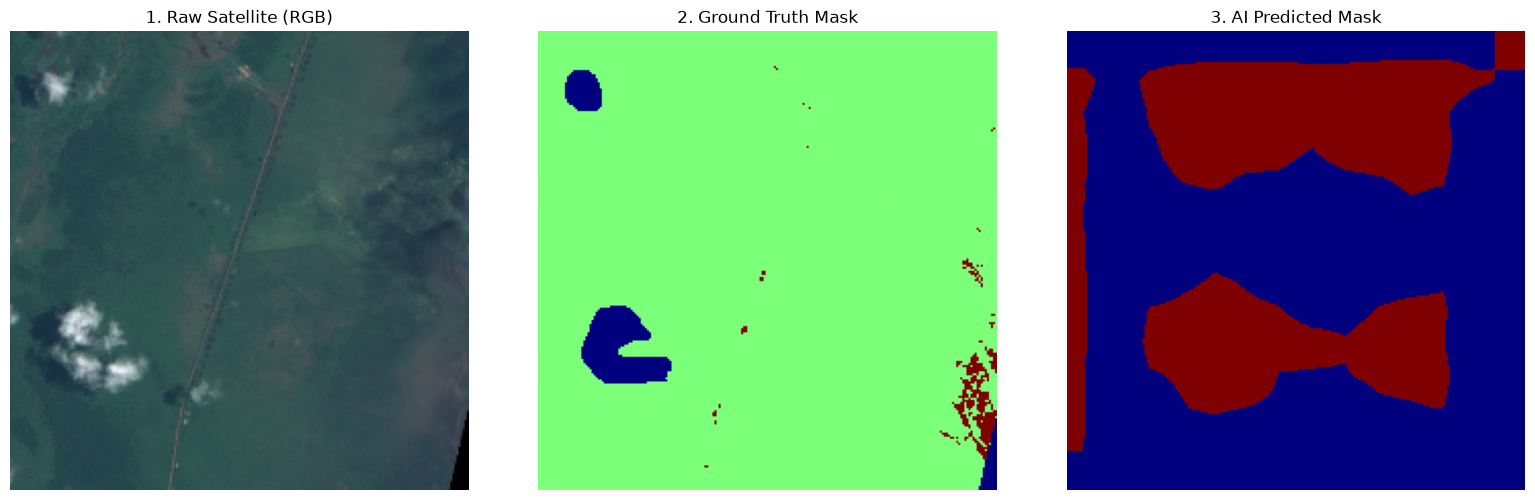

In [18]:
import torch
import matplotlib.pyplot as plt
import numpy as np

print("Preparing model for inference...")
task.eval()
device = torch.device("cuda")
task = task.to(device)

print("Fetching a validation image...")
sample = datamodule.val_dataset[0] 
image_tensor = sample["image"].unsqueeze(0).to(device)

print("Running AI prediction...")
with torch.no_grad():
    prediction = task(image_tensor)
    
    # THE FIX: Extract the raw PyTorch tensor from TerraTorch's ModelOutput wrapper
    logits = prediction.output if hasattr(prediction, "output") else prediction
    
    # Now torch.argmax will work perfectly
    predicted_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()

print("Plotting results...")
# Extract Red, Green, Blue bands and reorder to (RGB)
rgb_image = sample["image"][[2, 1, 0], :, :].cpu().numpy().transpose(1, 2, 0)

# Normalize strictly for visualization
rgb_image = (rgb_image - rgb_image.min()) / (rgb_image.max() - rgb_image.min() + 1e-8)
rgb_image = np.clip(rgb_image, 0, 1)

# Draw the comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("1. Raw Satellite (RGB)")
axes[0].axis("off")

axes[1].imshow(sample["mask"], cmap="jet")
axes[1].set_title("2. Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(predicted_mask, cmap="jet")
axes[2].set_title("3. AI Predicted Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [19]:
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping

# Save the checkpoint with the lowest validation loss
checkpoint_callback = ModelCheckpoint(
    dirpath="checkpoints/",
    filename="prithvi-flood-{epoch:02d}-{val_loss:.2f}",
    monitor="val_loss",
    mode="min",
    save_top_k=1
)

# Stop training automatically if the model stops improving for 5 epochs
early_stop_callback = EarlyStopping(
    monitor="val_loss", 
    patience=5, 
    mode="min"
)

trainer = L.Trainer(
    max_epochs=30, # Safe to set high; early stopping will catch it
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    callbacks=[checkpoint_callback, early_stop_callback],
    log_every_n_steps=10
)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [20]:
task = SemanticSegmentationTask(
    model_factory="EncoderDecoderFactory",
    model_args=model_args,
    loss="ce",
    lr=1.5e-4,
    optimizer="AdamW",
    optimizer_hparams={"weight_decay": 0.05},
    ignore_index=-1,    # Critical for accurate IoU
    plot_on_val=False
)

In [21]:
trainer.test(model=task, datamodule=datamodule)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

C:\Users\sunip\anaconda3\envs\venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/Accuracy       │    0.4924098551273346     │
│    test/Boundary_mIoU     │   0.004974390380084515    │
│   test/Class_Accuracy_0   │    0.9823296666145325     │
│   test/Class_Accuracy_1   │   0.002490066224709153    │
│       test/F1_Score       │     0.473413348197937     │
│        test/IoU_0         │    0.8914127945899963     │
│        test/IoU_1         │   0.002123142359778285    │
│    test/Pixel_Accuracy    │    0.8914378881454468     │
│         test/loss         │    0.48803502321243286    │
│         test/mIoU         │    0.4467679560184479     │
│      test/mIoU_Micro      │    0.8041388988494873     │
└───────────────────────────┴───────────────────────────┘

[{'test/loss': 0.48803502321243286,
  'test/Accuracy': 0.4924098551273346,
  'test/Boundary_mIoU': 0.004974390380084515,
  'test/Class_Accuracy_0': 0.9823296666145325,
  'test/Class_Accuracy_1': 0.002490066224709153,
  'test/F1_Score': 0.473413348197937,
  'test/IoU_0': 0.8914127945899963,
  'test/IoU_1': 0.002123142359778285,
  'test/Pixel_Accuracy': 0.8914378881454468,
  'test/mIoU': 0.4467679560184479,
  'test/mIoU_Micro': 0.8041388988494873}]

In [22]:
pip install rasterio tqdm

Note: you may need to restart the kernel to use updated packages.
